<h2 style="color: #6C63A8; font-family: 'Georgia'; font-weight: bold;">
    Analiza danych dotyczących transakcji sprzedażowych piekarni
</h2>

<h3 style="color: #B5ACDA; font-family: 'Georgia'; font-weight: bold;">
    1. Wstęp
</h3>
<h4 style="font-family: 'Georgia'; font-weight: bold;">
    1.1 Cel projektu
</h4>
<h5 style="font-family: 'Georgia';">
    Celem projektu jest przeprowadzenie analizy danych dotyczących transakcji sprzedażowych w piekarni z wykorzystaniem języka Python. Analiza ma na celu identyfikację najważniejszych trendów i zależności występujących w sprzedaży, ze szczególnym uwzględnieniem popularności poszczególnych produktów, zmian wielkości sprzedaży w czasie oraz zachowań zakupowych klientów.
</h5>

In [1]:
import pandas as pd
df = pd.read_csv("bakery_sales_dataset.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19321 entries, 0 to 19320
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             19321 non-null  str    
 1   Customer_ID          19321 non-null  str    
 2   Customer_Age         19321 non-null  int64  
 3   Customer_Gender      19321 non-null  str    
 4   Customer_Segment     19321 non-null  str    
 5   Loyalty_Member       19321 non-null  str    
 6   Date                 19321 non-null  str    
 7   Year                 19321 non-null  int64  
 8   Month                19321 non-null  int64  
 9   Day                  19321 non-null  int64  
 10  Day_of_Week          19321 non-null  str    
 11  Weekend              19321 non-null  str    
 12  Hour                 19321 non-null  int64  
 13  Time                 19321 non-null  str    
 14  Season               19321 non-null  str    
 15  Festival             3315 non-null   str    
 1

<h4 style="font-family: 'Georgia'; font-weight: bold;">
    1.2 Opis danych
</h4>
<h5 style="font-family: 'Georgia';">
    Do analizy wykorzystano zbiór
    <span style="color: #B5ACDA; font-weight: bold;">bakery_sales_dataset.csv</span>.
</h5>
<h5 style="font-family: 'Georgia';">
    Zbiór danych zawiera szczegółowe informacje dotyczące poszczególnych transakcji sprzedażowych zawartych w kilku piekarniach. Obejmuje on zakres dwóch lat – od 1 stycznia 2023 r. do 31 grudnia 2024 r. – i uwzględnia 35 unikalnych produktów oferowanych w trzech placówkach. Zbiór składa się z 19 321 rekordów i 40 kolumn obejmujących transakcje, charakterystykę klientów, szczegóły produktów, ceny, promocje, warunki środowiskowe, stan zapasów oraz wyniki działalności biznesowej.
</h5>
<h5 style="font-family: 'Georgia';">
    <span style="color: #B5ACDA; font-weight: bold;">Kolumny:</span>
</h5>
<ul style="font-family: 'Georgia'; line-height: 1.5;">
    <li><strong style="color: #C5BCE3;">Informacje o kliencie:</strong> wiek, płeć, segment klienta, członkostwo w programie lojalnościowym oraz oceny klienta.</li>
    <li><strong style="color: #C5BCE3;">Data i czas:</strong> daty transakcji, rok, miesiąc, dzień, dzień tygodnia, oznaczenie weekendu, godzina i dokładny czas.</li>
    <li><strong style="color: #C5BCE3;">Informacje o produkcie:</strong> nazwa produktu, kategoria, okres przydatności do spożycia, sposób przechowywania oraz stopień nietrwałości.</li>
    <li><strong style="color: #C5BCE3;">Ceny i sprzedaż:</strong> ilość, cena jednostkowa, koszt własny, cena sprzedaży, wysokość rabatu (w procentach) oraz łączna kwota rachunku.</li>
    <li><strong style="color: #C5BCE3;">Promocje i czynniki zewnętrzne:</strong> status promocji, rodzaj promocji, święta/wydarzenia, pora roku, warunki pogodowe oraz temperatura.</li>
    <li><strong style="color: #C5BCE3;">Zapasy i straty:</strong> liczba wyprodukowanych jednostek, liczba sprzedanych jednostek, liczba niesprzedanych jednostek, dostępny stan magazynowy oraz odsetek strat.</li>
    <li><strong style="color: #C5BCE3;">Wyniki biznesowe:</strong> zysk, metoda płatności oraz identyfikator sklepu.</li>
</ul>

In [2]:
df.head(5)

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,...,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
0,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST02,8,6,2,2,25.0,141.48,4
1,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Dry Storage,Low,ST02,4,3,1,1,25.0,39.96,4
2,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST03,3,2,1,1,33.3,103.83,4
3,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Dry Storage,Low,ST03,13,10,3,2,23.1,79.73,4
4,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Room Temperature,Very High,ST03,4,3,1,1,25.0,10.08,4


<h3 style="color: #B5ACDA; font-family: 'Georgia'; font-weight: bold;">
    2. Przygotowanie danych
</h3>
<h4 style="font-family: 'Georgia'; font-weight: bold;">
    2.1 Braki danych
</h4>

In [3]:
missing_values = df.isna().sum()

missing_data = pd.DataFrame({
    "Liczba braków": missing_values,
    "Udział braków (%)": (missing_values / len(df)) * 100
})

missing_data = missing_data[missing_data["Liczba braków"] > 0]

missing_data.style\
    .format({
        "Liczba braków": lambda x: f"{x:,.0f}".replace(",", " "),
        "Udział braków (%)": "{:.2f}%"
    })\
    .set_table_styles([
        {'selector': 'caption',
         'props': [('color', '#9188C5'),
                   ('font-size', '16px'),
                   ('font-weight', 'bold'),
                   ('font-family', 'Georgia')]},

        {'selector': 'th.col_heading',
         'props': [('background-color', '#6C63A8'),
                   ('color', 'white'),
                   ('font-family', 'Georgia'),
                   ('text-align', 'center')]},

        {'selector': 'th.row_heading',
         'props': [('background-color', '#C5BCE3'),
                   ('color', '#39345F'),
                   ('font-family', 'Georgia'),
                   ('text-align', 'left')]},

        {'selector': 'td',
         'props': [('background-color', 'transparent'),
                   ('color', 'inherit'),
                   ('text-align', 'center'),
                   ('font-family', 'Georgia')]}
    ])

,Liczba braków,Udział braków (%)
Festival,16 006,82.84%
Promotion_Type,13 826,71.56%


<h5 style="font-family: 'Georgia';">
    Największą liczbę brakujących danych zawierają zmienne: Festival (16 006 braków danych) oraz Promotion_Type (13 826 braki danych). Ich udział w ogólnej liczbie obserwacji przekracza 70% co stanowi dość istotny problem. Braki te mogą jednak wynikać ze specyfiki analizowanych transakcji – mogą wskazywać na zakupy dokonane poza okresem świątecznym lub bez udziału promocji.
</h5>

<Axes: >

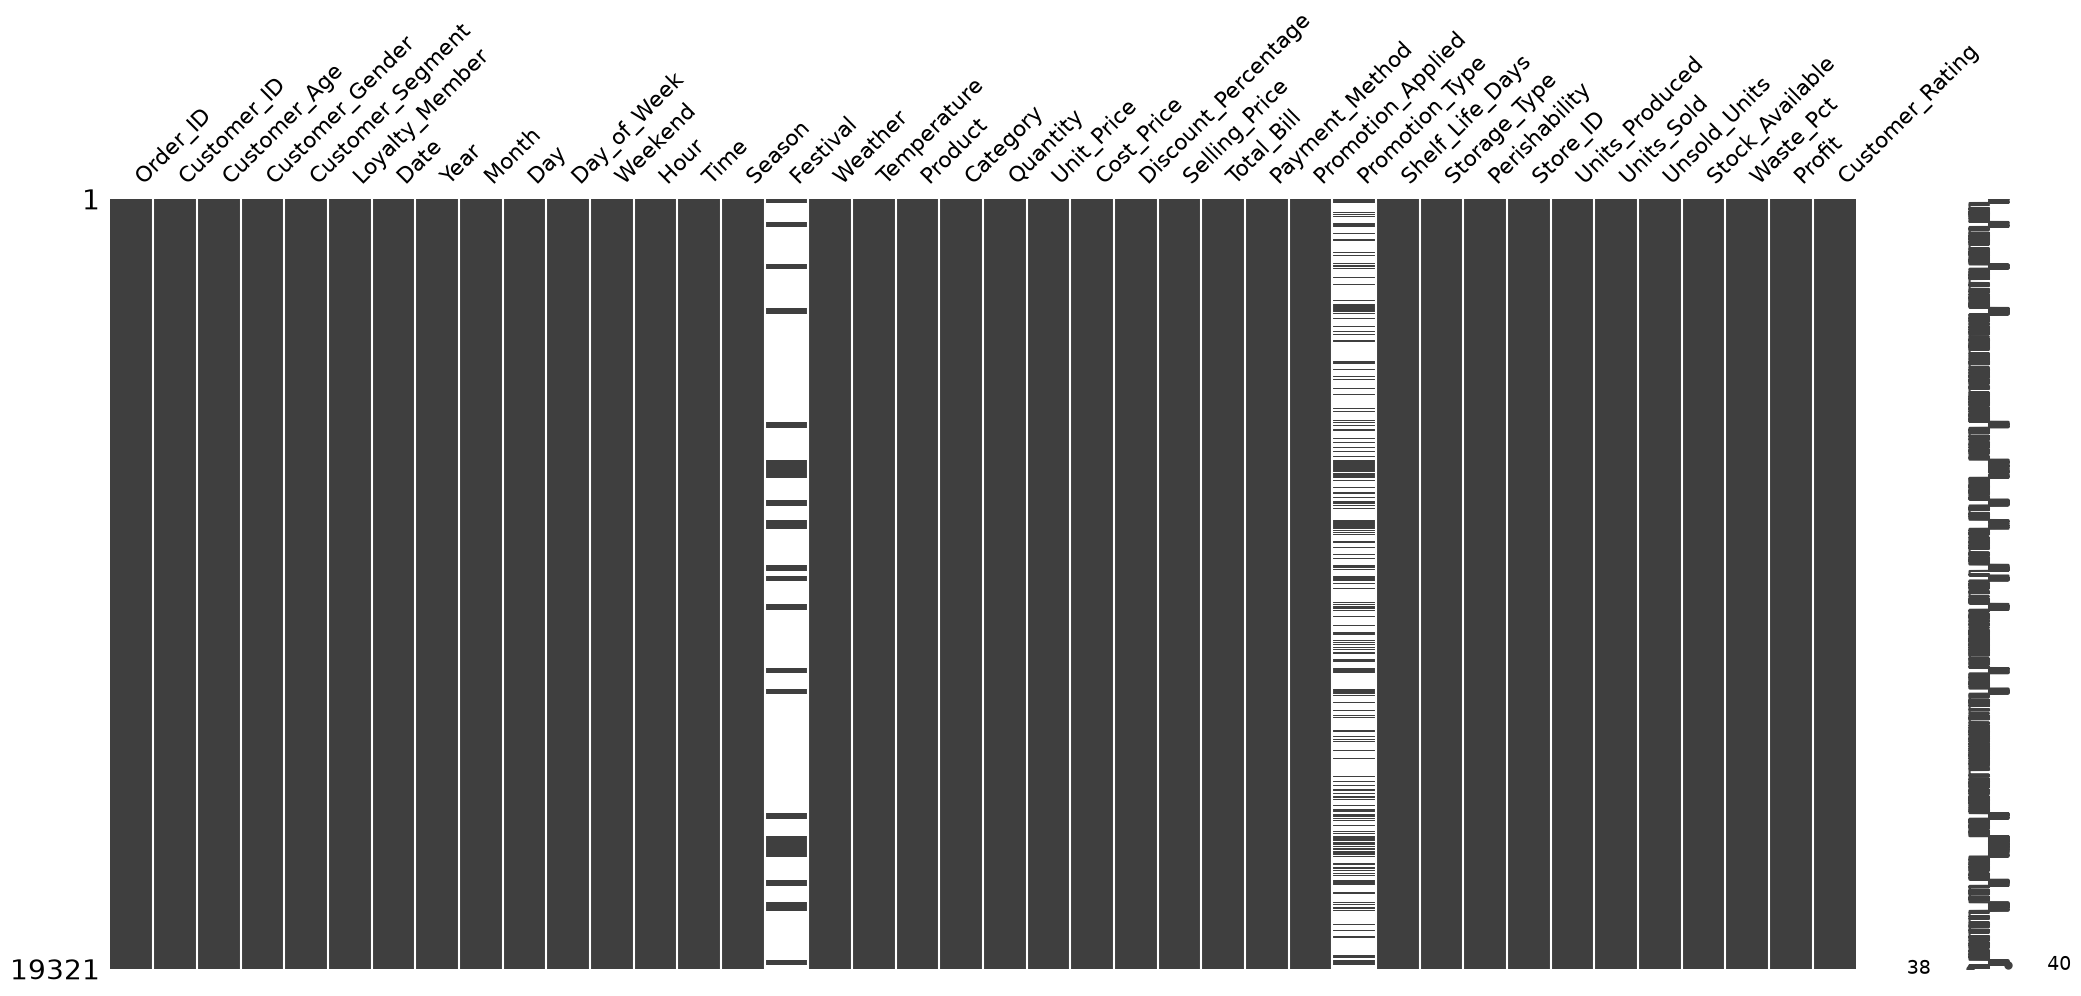

In [4]:
import missingno as msno
msno.matrix(df)

<Axes: >

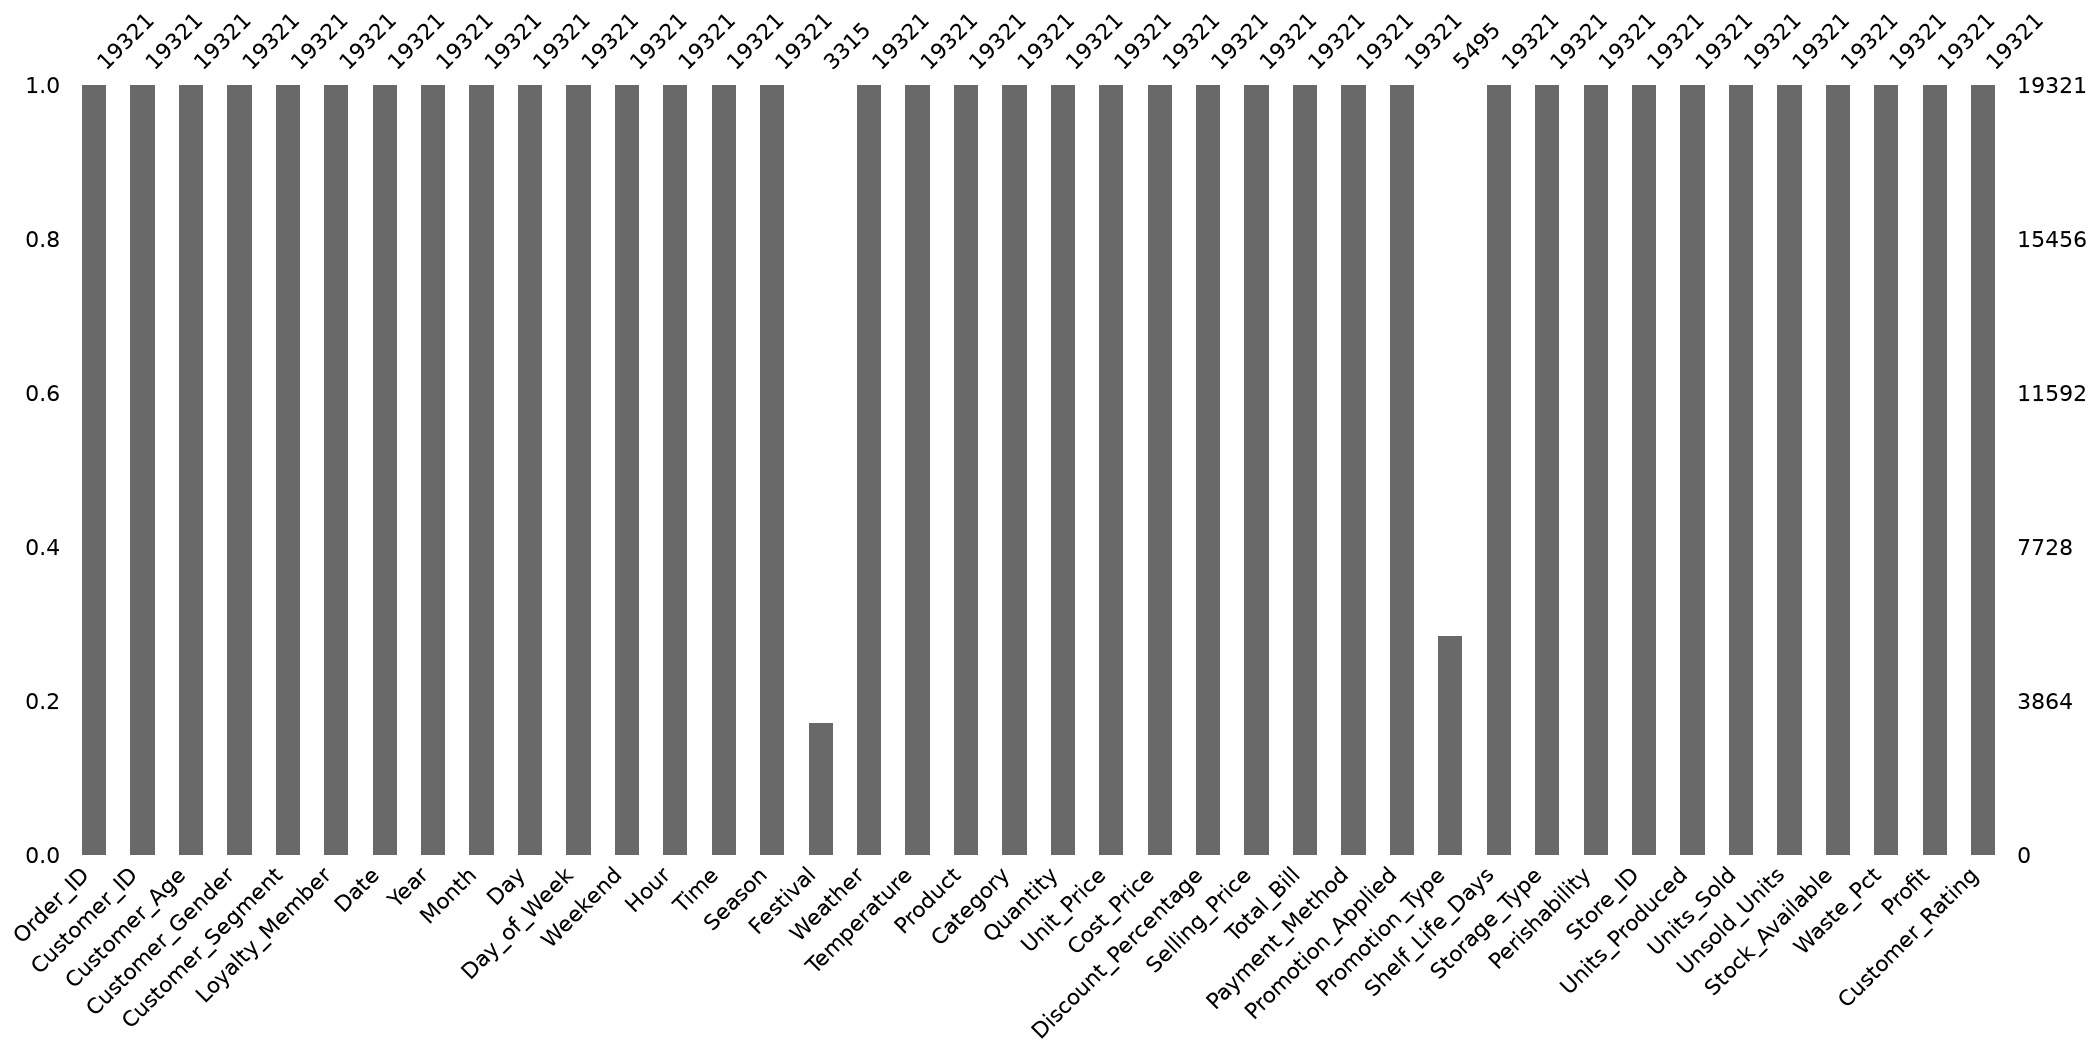

In [5]:
msno.bar(df)

!!!dodac reguły dla każdej zmiennej i sprawdzic ile danych ma błędy - zrobic wykresy itp. + duplikaty 

In [8]:
print(df.columns.tolist())

['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender', 'Customer_Segment', 'Loyalty_Member', 'Date', 'Year', 'Month', 'Day', 'Day_of_Week', 'Weekend', 'Hour', 'Time', 'Season', 'Festival', 'Weather', 'Temperature', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Cost_Price', 'Discount_Percentage', 'Selling_Price', 'Total_Bill', 'Payment_Method', 'Promotion_Applied', 'Promotion_Type', 'Shelf_Life_Days', 'Storage_Type', 'Perishability', 'Store_ID', 'Units_Produced', 'Units_Sold', 'Unsold_Units', 'Stock_Available', 'Waste_Pct', 'Profit', 'Customer_Rating']


In [11]:
def check_rules(df):
    rules = {
        #identyfikator
        "Order_ID niepuste": df["Order_ID"].notna(),
        "Customer_ID niepuste": df["Customer_ID"].notna(),
        "Store_ID niepuste": df["Store_ID"].notna(),

        # klient
        "Customer_Age > 0": df["Customer_Age"] > 0,
        "Customer_Age < 100": df["Customer_Age"] < 100,
        "Customer_Gender poprawne": df["Customer_Gender"].isin(["Male", "Female", "Other"]),
        "Customer_Segment niepuste": df["Customer_Segment"].notna(),
        "Loyalty_Member Yes/No": df["Loyalty_Member"].isin(["Yes", "No"]),
        "Customer_Rating 1-5": (df["Customer_Rating"] >= 1) & (df["Customer_Rating"] <= 5),

        #data i czas
        "Date niepuste": df["Date"].notna(),
        "Time niepuste": df["Time"].notna(),
        "Year >= 2000": df["Year"] >= 2000,
        "Month 1-12": (df["Month"] >= 1) & (df["Month"] <= 12),
        "Day 1-31": (df["Day"] >= 1) & (df["Day"] <= 31),
        "Day_of_Week poprawne": df["Day_of_Week"].isin([
            "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"
        ]),
        "Weekend Yes/No": df["Weekend"].isin(["Yes", "No"]),
        "Hour 0-23": (df["Hour"] >= 0) & (df["Hour"] <= 23),
        "Season poprawne": df["Season"].isin(["Spring", "Summer", "Autumn", "Winter"]),

        #podoga i święta
        "Weather niepuste": df["Weather"].notna(),
        "Temperature od -40 do 50": (df["Temperature"] >= -40) & (df["Temperature"] <= 50),
        "Festival niepuste": df["Festival"].notna(),

        #produkt
        "Product niepuste": df["Product"].notna(),
        "Category niepuste": df["Category"].notna(),
        "Shelf_Life_Days > 0": df["Shelf_Life_Days"] > 0,
        "Storage_Type niepuste": df["Storage_Type"].notna(),
        "Perishability niepuste": df["Perishability"].notna(),

        #ceny, promocje, sprzedaz
        "Quantity > 0": df["Quantity"] > 0,
        "Unit_Price > 0": df["Unit_Price"] > 0,
        "Cost_Price > 0": df["Cost_Price"] > 0,
        "Selling_Price > 0": df["Selling_Price"] > 0,
        "Total_Bill > 0": df["Total_Bill"] > 0,
        "Payment_Method niepuste": df["Payment_Method"].notna(),
        "Discount_Percentage 0-100": (df["Discount_Percentage"] >= 0) & (df["Discount_Percentage"] <= 100),
        "Promotion_Applied Yes/No": df["Promotion_Applied"].isin(["Yes", "No"]),
        "Promotion_Type niepuste": df["Promotion_Type"].notna(),
        "Selling_Price <= Unit_Price": df["Selling_Price"] <= df["Unit_Price"],
        "Selling_Price >= Cost_Price": df["Selling_Price"] >= df["Cost_Price"],
        "Total_Bill == Selling_Price * Quantity": (
            (df["Total_Bill"] - df["Selling_Price"] * df["Quantity"]).abs() < 0.1
        ),
        "Profit == (Selling_Price - Cost_Price) * Quantity": (
            (df["Profit"] - (df["Selling_Price"] - df["Cost_Price"]) * df["Quantity"]).abs() < 0.1
        ),

        #zapasy i straty
        "Units_Produced >= 0": df["Units_Produced"] >= 0,
        "Units_Sold >= 0": df["Units_Sold"] >= 0,
        "Unsold_Units >= 0": df["Unsold_Units"] >= 0,
        "Stock_Available >= 0": df["Stock_Available"] >= 0,
        "Waste_Pct 0-100": (df["Waste_Pct"] >= 0) & (df["Waste_Pct"] <= 100),
        "Units_Sold <= Units_Produced": df["Units_Sold"] <= df["Units_Produced"],
        "Sold + Unsold == Produced": (df["Units_Sold"] + df["Unsold_Units"]) == df["Units_Produced"],
    }
    return rules

#zastosowanie reguł
rules = check_rules(df)

#wydruk
for rule, result in rules.items():
    bledy = (~result).sum()
    print(f"{rule}: {result.all()} (błędów: {bledy})")



Order_ID niepuste: True (błędów: 0)
Customer_ID niepuste: True (błędów: 0)
Store_ID niepuste: True (błędów: 0)
Customer_Age > 0: True (błędów: 0)
Customer_Age < 100: True (błędów: 0)
Customer_Gender poprawne: True (błędów: 0)
Customer_Segment niepuste: True (błędów: 0)
Loyalty_Member Yes/No: True (błędów: 0)
Customer_Rating 1-5: True (błędów: 0)
Date niepuste: True (błędów: 0)
Time niepuste: True (błędów: 0)
Year >= 2000: True (błędów: 0)
Month 1-12: True (błędów: 0)
Day 1-31: True (błędów: 0)
Day_of_Week poprawne: True (błędów: 0)
Weekend Yes/No: True (błędów: 0)
Hour 0-23: True (błędów: 0)
Season poprawne: False (błędów: 6466)
Weather niepuste: True (błędów: 0)
Temperature od -40 do 50: True (błędów: 0)
Festival niepuste: False (błędów: 16006)
Product niepuste: True (błędów: 0)
Category niepuste: True (błędów: 0)
Shelf_Life_Days > 0: True (błędów: 0)
Storage_Type niepuste: True (błędów: 0)
Perishability niepuste: True (błędów: 0)
Quantity > 0: True (błędów: 0)
Unit_Price > 0: True (b

Jak często każda reguła jest łamana (naruszenia)?

In [15]:

rules = check_rules(df)

#sprawdzamy naruszenia reguł
bakery = {rule: ~result for rule, result in rules.items()}

#liczbę naruszeń
summary = {rule: result.sum() for rule, result in bakery.items()}

# 4. Wydruk podsumowania
print("Summary of Bakery:")
for rule, count in summary.items():
    print(f"{rule}: {count} Bakery")

Summary of Bakery:
Order_ID niepuste: 0 Bakery
Customer_ID niepuste: 0 Bakery
Store_ID niepuste: 0 Bakery
Customer_Age > 0: 0 Bakery
Customer_Age < 100: 0 Bakery
Customer_Gender poprawne: 0 Bakery
Customer_Segment niepuste: 0 Bakery
Loyalty_Member Yes/No: 0 Bakery
Customer_Rating 1-5: 0 Bakery
Date niepuste: 0 Bakery
Time niepuste: 0 Bakery
Year >= 2000: 0 Bakery
Month 1-12: 0 Bakery
Day 1-31: 0 Bakery
Day_of_Week poprawne: 0 Bakery
Weekend Yes/No: 0 Bakery
Hour 0-23: 0 Bakery
Season poprawne: 6466 Bakery
Weather niepuste: 0 Bakery
Temperature od -40 do 50: 0 Bakery
Festival niepuste: 16006 Bakery
Product niepuste: 0 Bakery
Category niepuste: 0 Bakery
Shelf_Life_Days > 0: 0 Bakery
Storage_Type niepuste: 0 Bakery
Perishability niepuste: 0 Bakery
Quantity > 0: 0 Bakery
Unit_Price > 0: 0 Bakery
Cost_Price > 0: 0 Bakery
Selling_Price > 0: 0 Bakery
Total_Bill > 0: 0 Bakery
Payment_Method niepuste: 0 Bakery
Discount_Percentage 0-100: 0 Bakery
Promotion_Applied Yes/No: 0 Bakery
Promotion_Type

Jaki procent danych ma błędy

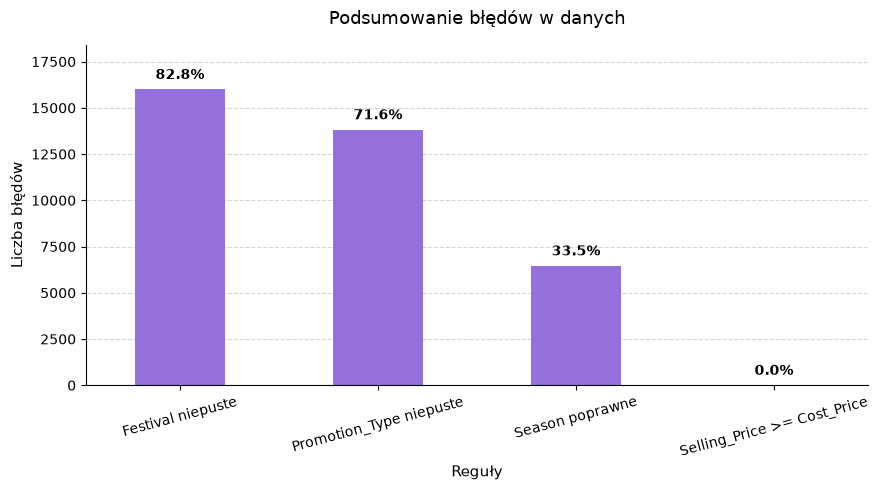

In [28]:
import matplotlib.pyplot as plt
# Wykres naruszeń:
bakery_counts = pd.Series(summary)
bakery_counts = bakery_counts[bakery_counts > 0].sort_values(ascending=False)

ax = bakery_counts.plot(kind='bar', figsize=(9, 5), color = 'mediumpurple', width = 0.45)
plt.title('Podsumowanie błędów w danych', fontsize=13, pad=15)
plt.xlabel('Reguły', fontsize=11)
plt.ylabel('Liczba błędów', fontsize=11)
plt.xticks(rotation=15)

ax.set_ylim(0, bakery_counts.max() * 1.15)
            
# Dodaję procenty nad słupki:
procenty = [f'{(v / len(df)) * 100:.1f}%' for v in bakery_counts]
ax.bar_label(ax.containers[0], labels=procenty, padding=5, fontsize=10, fontweight= 'bold')

ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_axisbelow(True)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

Boxplot dla wartości odstających

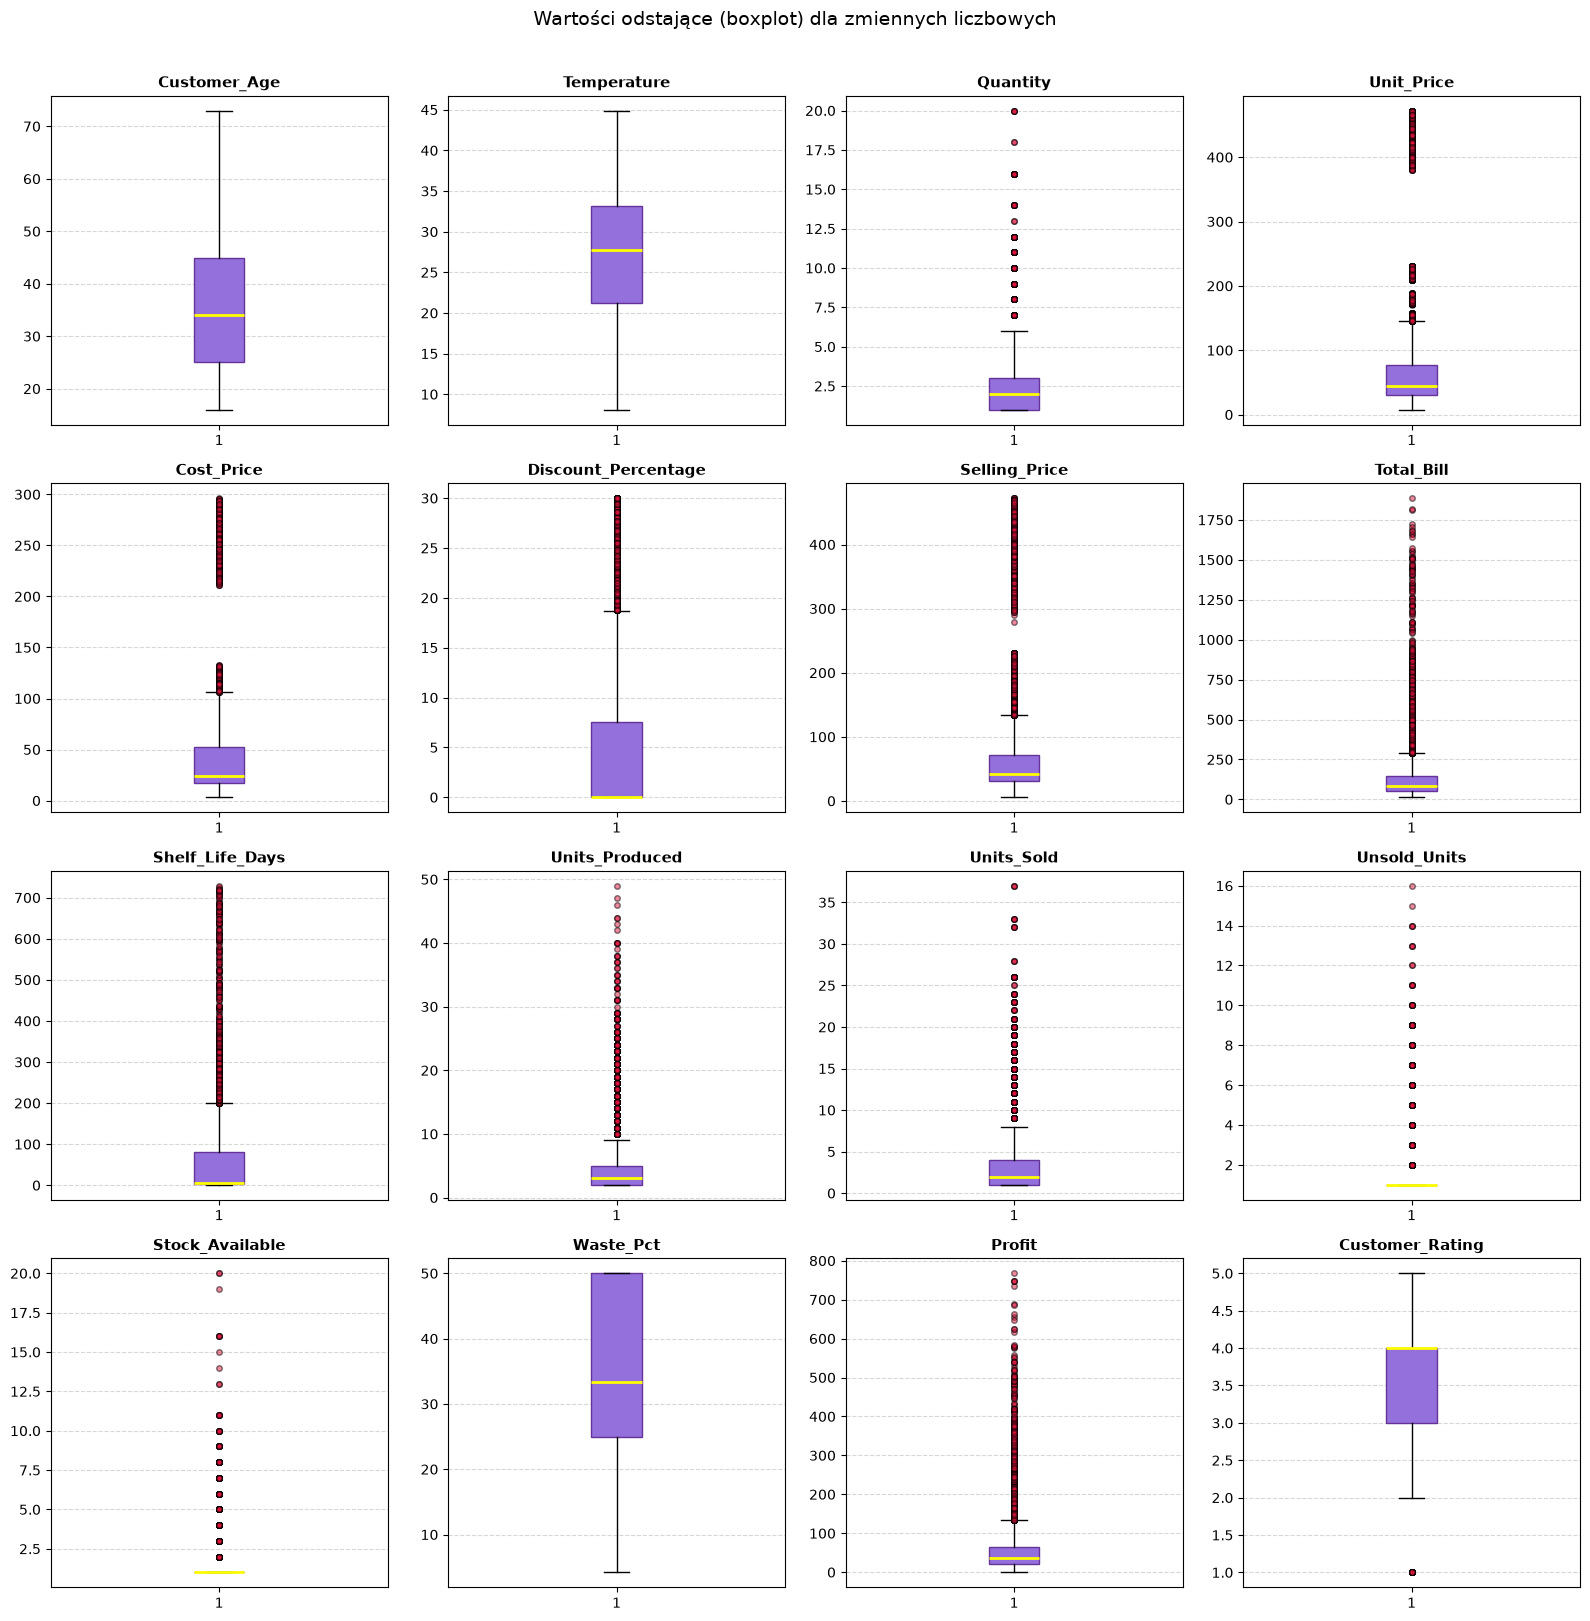

Liczba wartości odstających (metoda IQR):
Customer_Age: 0 (0.00%)
Temperature: 0 (0.00%)
Quantity: 712 (3.69%)
Unit_Price: 2541 (13.15%)
Cost_Price: 1912 (9.90%)
Discount_Percentage: 1101 (5.70%)
Selling_Price: 2578 (13.34%)
Total_Bill: 2637 (13.65%)
Shelf_Life_Days: 2340 (12.11%)
Units_Produced: 1298 (6.72%)
Units_Sold: 1048 (5.42%)
Unsold_Units: 1590 (8.23%)
Stock_Available: 1091 (5.65%)
Waste_Pct: 0 (0.00%)
Profit: 2280 (11.80%)
Customer_Rating: 378 (1.96%)


In [ ]:
import matplotlib.pyplot as plt
import math

#kolumny liczbowe
kolumny_liczbowe = [
    'Customer_Age', 'Temperature', 'Quantity', 'Unit_Price',
    'Cost_Price', 'Discount_Percentage', 'Selling_Price', 'Total_Bill',
    'Shelf_Life_Days', 'Units_Produced', 'Units_Sold', 'Unsold_Units',
    'Stock_Available', 'Waste_Pct', 'Profit', 'Customer_Rating'
]

#siatka wykresow
n_cols = 4
n_rows = math.ceil(len(kolumny_liczbowe) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(kolumny_liczbowe):
    axes[i].boxplot(
        df[col].dropna(),
        patch_artist=True,
        boxprops=dict(facecolor='mediumpurple', color='rebeccapurple'),
        medianprops=dict(color='yellow', linewidth=2),
        flierprops=dict(marker='o', markerfacecolor='crimson', markersize=4, alpha=0.5)
    )
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

#ukrywanie pustycch okiena
for j in range(len(kolumny_liczbowe), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Wartości odstające (boxplot) dla zmiennych liczbowych', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

print("Liczba wartości odstających (metoda IQR):")
for col in kolumny_liczbowe:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    dolna = Q1 - 1.5 * IQR
    gorna = Q3 + 1.5 * IQR
    
    odstajace = ((df[col] < dolna) | (df[col] > gorna)).sum()
    pct = (odstajace / len(df)) * 100
    print(f"{col}: {odstajace} ({pct:.2f}%)")